# Hyperbolic Cavity with $d=6.25$ nm and $R=5$ nm

This notebook presents the few-mode fitting and subsequent master-equation analysis for a hyperbolic cavity with dimensions $d=6.25\,\mathrm{nm}$ and $R=5\,\mathrm{nm}$. The workflow follows the same sequence as the other few-mode notebooks in this repository: construct the spectral density, fit its resonant contribution, inspect the light–matter figures of merit, and study the effective spectrum and time dynamics.

## Tools and utilities

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle

# Request 64-bit arithmetic from the optional fitting backend before it loads.
os.environ.setdefault('JAX_ENABLE_X64', 'True')
plt.style.use("https://johannesfeist.eu/misc/jf_cb.mplstyle")

import sys
sys.path.append('..')

from methods.plotcolored import plotcolored
from methods.tools import debye_e_nm

In [2]:
# dipole moment
mu_D = 1.0  # Debye
mu_e_nm = mu_D * debye_e_nm  # e nm
# The intrinsic homogeneous linewidth used in the light–matter analysis.
gamma_e_eV = 0.04e-3  # eV

## Spectral Density for the mode

The input file contains Purcell-factor spectra for a family of cavities with fixed aspect ratio $d/R=1.25$. We first load the complete dataset and convert its frequency axis from THz to photon energy in eV.

In [3]:
# The text file contains a five-line metadata header.
file_path = '../data/DAchS-d-R-1_AR1.25_Fp_near46THz.txt'
dataB = np.loadtxt(file_path, skiprows=5)

In [4]:
# Frequency grid in THz and cavity dimensions in nm.
freq_ls = np.array(dataB[:,0])
ar = 1.25
R_ls = np.linspace(5, 30, 5)
d_ls = ar * R_ls

# Each remaining column contains the Purcell factor for one radius.
Fp = np.array(dataB[:,1:])

In [5]:
# Convert frequency from THz to photon energy in eV.
w = freq_ls / 241.799
k0 = 2.0 * np.pi / (1240 / w)
eps0 = 55.264 * 1e-3  # e^2 eV^-1 nm^-1
J0 = k0**3 / (6.0 * np.pi**2 * eps0) 

# Dipole-moment-normalized spectral density for every cavity radius.
J = Fp * J0[:,None]
J_target = J[:,0]  # Target spectral density for R = 5 nm.

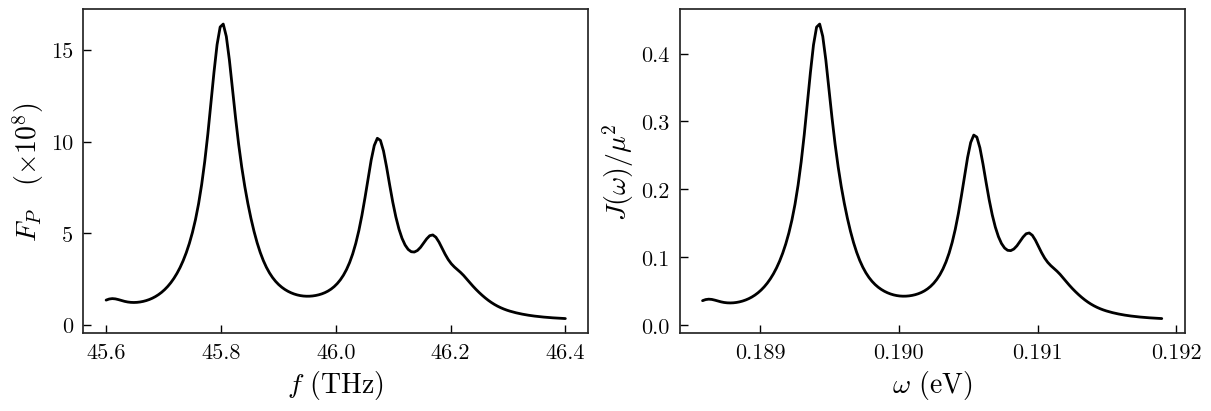

In [6]:
fig, ax = plt.subplots(figsize=(12,4), nrows=1, ncols=2)
ax[0].plot(freq_ls, Fp[:,0]*1e-8)
ax[1].plot(w, J_target)

ax[0].set_ylabel(r'$F_P \quad (\times 10^8)$', fontsize=20)
ax[0].set_xlabel(r'$f \text{ (THz)}$', fontsize=20)

ax[1].set_xlabel(r'$\omega \text{ (eV)}$', fontsize=20)
ax[1].set_ylabel(r'$J(\omega)/\mu^2$', fontsize=20);

### Electric Field Profile

We plot the corresponding electric field profile of this mode.

In [7]:
from scipy.interpolate import griddata
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

In [8]:
file_path = '../data/DAchS-6.25-5-1_field_profile.txt'
dataB = np.loadtxt(file_path, skiprows=8)

x, y, z = dataB[:,0], dataB[:,1], dataB[:,2]

In [9]:
xs = np.linspace(0.0, 10E-9, 200)
ys = np.linspace(-9E-9, 5E-9, 200)
X, Y = np.meshgrid(xs, ys)
Z = griddata((x, y), z, (X, Y), method='linear')  # or 'linear'
Z = np.where(Z < 0, 1, Z)

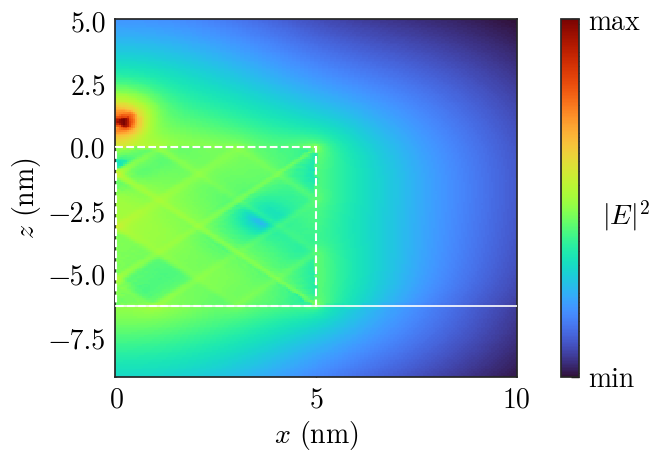

In [10]:
fig, ax = plt.subplots()
pcm = ax.pcolormesh(X*1e9, Y*1e9, Z, norm=LogNorm(), rasterized=True)
cbar = fig.colorbar(pcm, ax=ax, shrink=1.0)
cbar.ax.set_ylabel(r'$|E|^2$', rotation=0, fontsize=20, labelpad=-10)
cbar.set_ticks([Z.min(), Z.max()])
cbar.set_ticklabels(['min', 'max'], fontsize=20) 

ax.set_xlabel(r'$x \text{ (nm)}$', fontsize=20)
ax.set_ylabel(r'$z \text{ (nm)}$', fontsize=20)
ax.tick_params(axis='both', labelsize=20)

ax.axhline(y=-6.25, color='white', lw=1.2, zorder=3)

cavity = Rectangle((0, -6.25), 5, 6.25,
                   linewidth=1.5,
                   edgecolor='white',
                   facecolor='none',
                   linestyle='--',
                   zorder=3)
ax.add_patch(cavity);

## Target Spectral Density

We now select the first spectrum, corresponding to $R=5\,\mathrm{nm}$ and $d=6.25\,\mathrm{nm}$. The spectral density remains normalized by the squared dipole moment, allowing the same fitted environment to be used for several emitter dipoles later in the notebook.

The resonant response is represented by the few-mode model

$$J_{\mathrm{fm}}(\omega)=\frac{\mu^2}{\pi}\operatorname{Im}\left[\mathbf g^T(\widetilde{\mathbf H}-\omega)^{-1}\mathbf g\right],$$

where $\widetilde{\mathbf H}=\mathbf H-i\,\mathrm{diag}(\boldsymbol\kappa)/2$. The values below initialize the numerical fit; they are not the final physical parameters.

In [11]:
# The fitting class wraps the external spectral-density fitter and keeps
# the fitted parameters in the NumPy format used by the analysis below.
from methods.apply_few_mode import FewModeFit

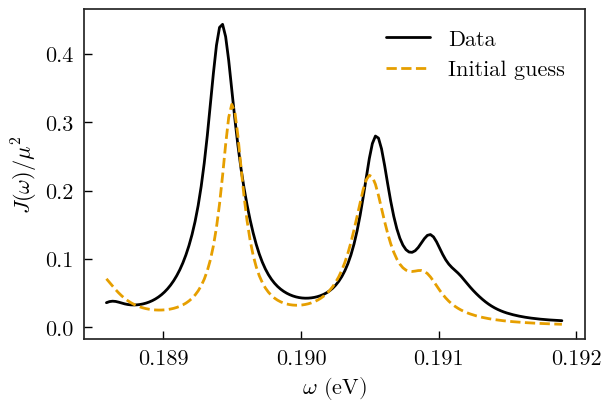

In [12]:
# Initialize a five-mode model near the resonances of interest. The mode
# energies, linewidths, and couplings are starting values for the fit.
H = np.diag([0.1885, 0.1895, 0.1905, 0.1909, 0.1912])
Nm = H.shape[0]
K = np.r_[4e-4, 2e-4, 3e-4, 3e-4, 3e-4]
g = np.r_[[7E-3, 10e-3, 10E-3, 5E-3, 4e-4]].reshape(1, Nm)

fmc = FewModeFit(w, J_target, H, K, g)
fmc.initialize();

Fit error: 0.0217625


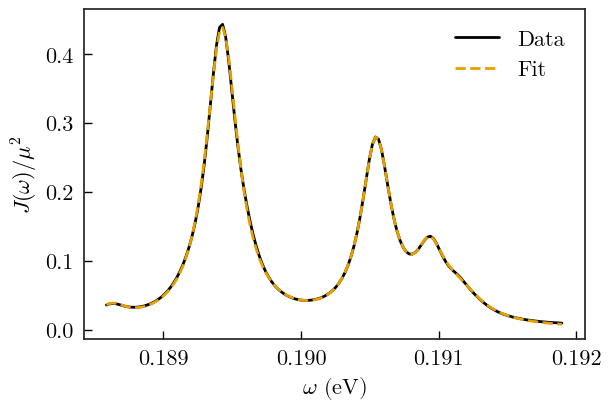

In [13]:
fmc.fit();

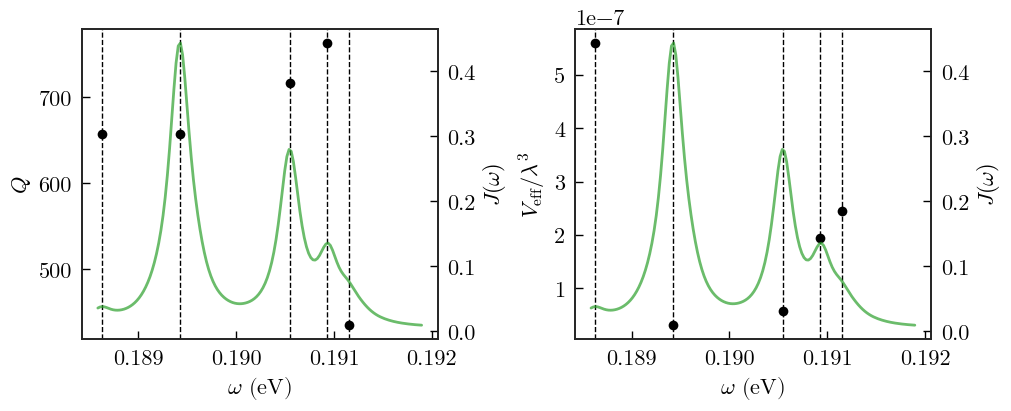

In [14]:
# Diagonalize the fitted lossy Hamiltonian and obtain the mode-resolved
# resonance energies, quality factors, and normalized mode volumes.
Omega, Q, Veff_norm = fmc.compute_figures_of_merit()

In [15]:
# Interpolate the fitted resonant contribution across the full data range.
Jfit_interp_func = fmc.create_interpolator(w_min=w.min(), w_max=w.max())
w_interp = np.linspace(w.min(), w.max(), 400)
Jfit_interp = Jfit_interp_func(w_interp)

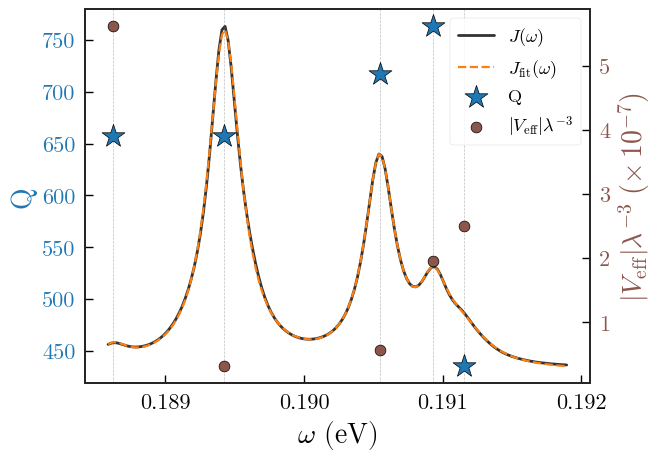

In [16]:
fig, ax1 = plt.subplots()

# Colors
c_Q     = '#1f77b4'   # blue, for Q (left axis)
c_V     = '#8c564b'   # brown, for V_eff (right axis)
c_true  = '#333333'   # near-black, true J
c_fit   = '#ff7f0e'   # orange, few-mode fit

# Spectral density curves (use a hidden 3rd axis so they don't conflict with left scale)
ax_J = ax1.twinx()
ax_J.plot(w, J_target, color=c_true, lw=2, label=r'$J(\omega)$')
ax_J.plot(w, Jfit_interp_func(w), color=c_fit, lw=1.6, ls='--', label=r'$J_{\text{fit}}(\omega)$')
ax_J.set_yticks([])              # hide ticks
ax_J.spines['right'].set_visible(False)
ax_J.set_zorder(1)               # behind markers

# Vertical guides at mode frequencies (optional, very faint)
for wi in np.real(Omega):
    ax1.axvline(wi, color='gray', lw=0.5, ls='--', alpha=0.5, zorder=0)

# Q on left axis
ax1.scatter(np.real(Omega), Q, marker='*', s=300,
            color=c_Q, edgecolor='black', lw=0.5,
            label='Q', zorder=3)
ax1.set_xlabel(r'$\omega$ (eV)', fontsize=20)
ax1.set_ylabel('Q', color=c_Q, fontsize=20)
ax1.tick_params(axis='y', labelcolor=c_Q)
ax1.set_zorder(2)
ax1.patch.set_visible(False)     # let ax_J show through

# V_eff on right axis
ax2 = ax1.twinx()
ax2.scatter(np.real(Omega), np.abs(Veff_norm)*1e7, marker='o', s=60,
            color=c_V, edgecolor='black', lw=0.5,
            label=r'$|V_\mathrm{eff}| \lambda^{-3}$', zorder=3)
ax2.set_ylabel(r'$|V_\mathrm{eff}| \lambda^{-3} \,\, (\times \, 10^{-7})$', color=c_V, fontsize=20)
ax2.tick_params(axis='y', labelcolor=c_V)
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# Combined legend
handles = (ax_J.get_lines() +
           [ax1.collections[0], ax2.collections[0]])
labels  = [h.get_label() for h in handles]
ax1.legend(handles, labels, frameon=True, fontsize=13)

In [17]:
# Complex emitter-mode couplings in the diagonal mode basis.
g_tilde = fmc.g_tilde

In [18]:
H, kappas, gs = fmc.fitted_parameters()

In [19]:
data = {
    'fit': {
        'w': w, 
        'J': J, 
        'w_interp': w_interp, 
        'Jfit_interp': Jfit_interp
    },    
    'coupled_modes': {
        'H': H, 
        'kappas': kappas, 
        'g': gs
    },
    'uncoupled_modes': {
        'Omega': Omega,
        'Q': Q,
        'Veff_norm': Veff_norm,
        'gs': g_tilde
    }
}

with open('few_mode_fits/DAchS-6.5-5-1_5modes_fit.pickle', 'wb') as handle:
    pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Load saved few-mode fitting results (optional)

Run this section only when loading a previously saved fit—for example, to skip the optimization and proceed directly to the light–matter analysis. When running the notebook from the beginning, these cells simply reload the results saved above.

In [34]:
# load data
filename = 'few_mode_fits/DAchS-6.5-5-1_5modes_fit.pickle'
with open(filename, 'rb') as handle:
    data = pickle.load(handle)

In [35]:
w, J = data['fit']['w'], data['fit']['J']
w_interp, Jfit_interp = data['fit']['w_interp'], data['fit']['Jfit_interp']
H = data['coupled_modes']['H']
kappas = data['coupled_modes']['kappas']
gs = data['coupled_modes']['g']
Nm = kappas.shape[0]

## Spectrum of the effective Hamiltonian


We calculate the spectrum of the effective non-Hermitian Hamiltonian

$$\hat{\mathcal H}_\mathrm{eff}=\hat H'_\mathrm{S}-\frac{i}{2}\sum_i\kappa_i\hat a_i^\dagger\hat a_i-\frac{i}{2}[\gamma_e+\gamma_\mathrm{pert}(\omega_e)]\hat b^\dagger\hat b.$$

Here, $\hat H'_\mathrm{S}$ contains the fitted few-mode Hamiltonian, dipole-scaled light–matter couplings, and the Lamb-shift-corrected emitter energy $\tilde{\omega}_e$.


In [20]:
from methods.mastereq import MasterEquationQtp

The effective quantum model is constructed from the fitted coupled-mode Hamiltonian, mode decay rates, and emitter-mode couplings. Restricting the Hilbert space to a single excitation is sufficient for the linear-response dynamics considered here.

In [21]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);

In [22]:
we_ls = np.linspace(w[0], w[-1], 50)
vals, vecs = meq.get_Heff_dispersion(
    we_ls, mu=mu_e_nm, gamma_e=gamma_e_eV
)

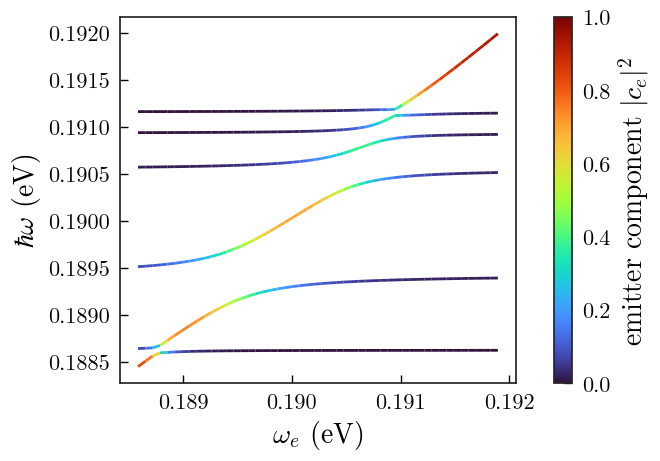

In [23]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots()
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in its eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\omega_e \text{ (eV)}$", fontsize=20)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=20)
cb = plt.colorbar(im, ax=ax)
cb.set_label(r"emitter component $|c_e|^2$", fontsize=20)

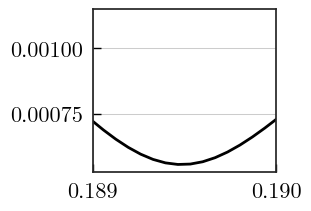

In [24]:
# find splitting
spl = vals[:,3].real - vals[:,2].real
fig, ax = plt.subplots(figsize=(3,2))
ax.plot(we_ls, spl)
ax.set_xlim(0.189, 0.19)
ax.grid()

In [25]:
# Locate the bare emitter energy at which the selected branches have their minimum splitting.
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([0.00055536]), array([0.18946416]))

### Strong-coupling diagnostic

The following cells retain the original diagnostic based on the fitted mode closest to the target resonance. Two linewidth-based criteria, $C_1$ and $C_2$, are evaluated as functions of the emitter dipole moment to estimate the onset of resolvable light–matter coupling. Here we assume a single Lorentzian mode coupled to the emitter.

In [26]:
g_target = g_tilde[1] # V/nm
gamma_c = np.real(Omega[1]) / Q[1]  # eV
gamma_e = gamma_e_eV

In [27]:
mu_ls = np.linspace(0.2, 1.2, 20) # Debye
mu_ls = mu_ls * debye_e_nm

res = {'C1': [], 'C2': []}
for mu_i in mu_ls:
    Omega_R = 2 * np.real(g_target) * mu_i
    C1 = Omega_R / (np.abs(gamma_c-gamma_e)/2)
    C2 = Omega_R / np.sqrt(gamma_c**2 / 2 + gamma_e**2 / 2) 
    res['C1'].append(C1)
    res['C2'].append(C2)

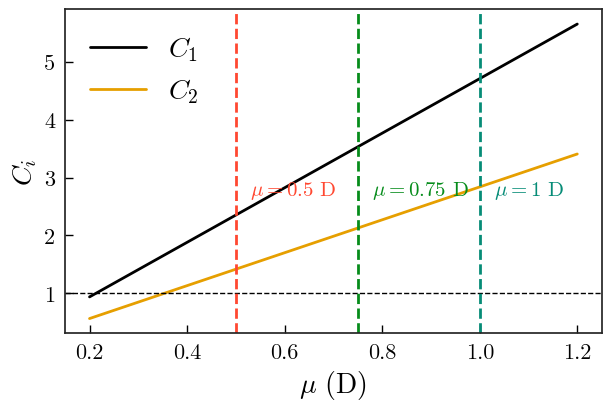

In [28]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(mu_ls / debye_e_nm, res['C1'], label=r'$C_1$')
ax.plot(mu_ls / debye_e_nm, res['C2'], label=r'$C_2$')
ax.axhline(1, linestyle='--', lw=1)
ax.legend(prop={'size': 20})

ax.axvline(0.5, linestyle='--', color='#FF4831')
ax.text(0.5+0.03, 2.7, r'$\mu = 0.5 \text{ D}$', fontsize=15, color='#FF4831')

ax.axvline(0.75, linestyle='--', color='#068C1B')
ax.text(0.75+0.03, 2.7, r'$\mu = 0.75 \text{ D}$', fontsize=15, color='#068C1B')

ax.axvline(1.0, linestyle='--', color='#068C77')
ax.text(1.0+0.03, 2.7, r'$\mu = 1 \text{ D}$', fontsize=15, color='#068C77')

ax.set_xlabel(r'$\mu \text{ (D)}$', fontsize=20)
ax.set_ylabel(r'$C_i$', fontsize=20);

In [29]:
# compute threshold for C1
C1_vals = np.array(res['C1'])
dC1_vals = np.abs(C1_vals - 1.0)
C1_indx = np.where(dC1_vals == np.min(dC1_vals))
print("For C1:\t", mu_ls[C1_indx][0] / debye_e_nm)

# compute threshold for C2
C2_vals = np.array(res['C2'])
dC2_vals = np.abs(C2_vals - 1.0)
C2_indx = np.where(dC2_vals == np.min(dC2_vals))
print("For C2:\t", mu_ls[C2_indx][0] / debye_e_nm)

For C1:	 0.2
For C2:	 0.35789473684210527


## Time dynamics

Finally, we propagate the dynamics of an initially excited emitter coupled to the fitted photonic modes. 


In [30]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [31]:
# Tune the emitter to the energy selected from the avoided-crossing analysis.
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_ls[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2], [1]], shape=(7, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [32]:
tsfs, sol = meq.solve(t_max=5e4, n_t=3000)

In [ ]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(ncol=2);
ax.set_yscale('log')